<div dir="rtl" lang="fa">

# فاز اول — شناخت مطالعه، داده و آمار توصیفی

مسیر ج: NACC (UDS + MRI)

هدف این نوت‌بوک: قبل از هر استنباط، منشأ داده، واحد مشاهده، نوع مطالعه و توزیع متغیرهای اصلی را مشخص کنیم.

خروجی نهایی فاز اول:
- همین نوت‌بوک (کد قابل بازتولید)
- `PROJECT_CARD.md`
- README به‌روز
- برچسب `phase-1`

</div>

<div dir="rtl" lang="fa">

## آماده‌سازی

بارگذاری کتابخانه‌ها و خواندن سه فایل خام.

</div>

In [ ]:
from pathlib import Path

import pandas as pd

ROOT = Path("../..").resolve()
RAW = ROOT / "data" / "raw"

uds = pd.read_csv(RAW / "udslong_imputed.csv")
mri = pd.read_csv(RAW / "mriscanclean.csv")
adj = pd.read_csv(RAW / "combined_adjacency_matrix.csv", index_col=0)

print("UDS:", uds.shape)
print("MRI:", mri.shape)
print("ADJ:", adj.shape)

<div dir="rtl" lang="fa">

## تسک‌های مشترک

۱. منشأ داده و سازوکار جمع‌آوری  
۲. واحد مشاهده و ساختار داده  
۳. نمونه‌گیری، انتخاب و قابلیت تعمیم  
۴. طبقه‌بندی متغیرها  
۵. ممیزی کیفیت داده  
۶. جدول‌های فراوانی و توزیع تجربی  
۷. مرکز و پراکندگی  
۸. مصورسازی درست  
۹. مقایسه توصیفی اولیه  
۱۰. نهایی کردن سؤال آماری

## الزامات مسیر ج

ج۱. نقشه زیرمجموعه UDS و MRI  
ج۲. ساختار شرکت‌کننده و مراجعه  
ج۳. اتصال UDS و MRI  
ج۴. داده‌های گمشده و انتخاب شدن نمونه چندوجهی  
ج۵. خلاصه مشترک شناختی و تصویربرداری

</div>

<div dir="rtl" lang="fa">

### تسک ۱ — منشأ داده و سازوکار جمع‌آوری

#### منبع رسمی داده
داده این پروژه از **National Alzheimer's Coordinating Center (NACC)** آمده است. منبع اصلی بخش بالینی، مجموعه استاندارد **Uniform Data Set (UDS)** است که از سال ۲۰۰۵ در مراکز **Alzheimer's Disease Research Centers (ADRCs)** جمع‌آوری می‌شود. بخش تصویربرداری نیز اندازه‌های کمی MRI مربوط به همان شرکت‌کنندگان است که در مستندات Imaging به‌صورت SCAN & CLARiTI ثبت شده‌اند.

در این درس از کل پایگاه NACC استفاده نمی‌شود. تحلیل فقط روی زیرمجموعه‌ای انجام می‌شود که تیم دستیاری تحویل داده است:

- `udslong_imputed.csv` : وجه بالینی UDS
- `mriscanclean.csv` : وجه تصویربرداری MRI
- `combined_adjacency_matrix.csv` : ماتریس همسایگی نواحی مغزی (داده فردی نیست)

#### دوره جمع‌آوری
UDS از سال ۲۰۰۵ تاکنون به‌صورت طولی جمع می‌شود و شرکت‌کنندگان معمولاً در بازه‌های تقریبی سالانه پیگیری می‌شوند. فایل‌های این پروژه نسخه آماده‌شده و محدودشده همان داده برای درس هستند؛ بنابراین دوره دقیق freeze زیرنمونه، همان چیزی است که تیم دستیاری اعلام کرده و کل تاریخچه خام NACC در اختیار ما نیست.

#### روش کلی تولید داده
داده UDS با پروتکل استاندارد در مراجعات بالینی ثبت می‌شود. اطلاعات از معاینه و مشاهده شرکت‌کننده و نیز گزارش همراه (معمولاً خانواده یا دوست نزدیک) گرفته می‌شود. تشخیص شناختی توسط پزشک یا کمیته توافقی مرکز تعیین می‌گردد.

داده MRI از تصویربرداری ساختاری مغز به دست آمده و سپس به اندازه‌های کمی ناحیه‌ای تبدیل شده است؛ در فایل ما عمدتاً حجم ماده خاکستری (`_GVOL`) و ضخامت متوسط قشر (`_AVGTH`) وجود دارد.

#### نوع مطالعه
این داده حاصل **مطالعه مشاهده‌ای بالینی** است، نه آزمایش تصادفی و نه پیمایش احتمالی جمعیت عمومی. ترکیبی از:

- مراجعه / ارزیابی بالینی استاندارد (UDS)
- تصویربرداری مغزی (MRI)

است.

#### محدودیت دسترسی
دسترسی ما محدود به فایل‌های عمومی/تحویلی مسیر ج است. داده controlled-access جداگانه درخواست نشده و استفاده نمی‌شود. همچنین ماژول‌های فرعی مثل FTLD، LBD یا MDS خارج از دامنه این پروژه هستند.

</div>

<div dir="rtl" lang="fa">

### تسک ۲ — واحد مشاهده و ساختار داده

در فایل‌های UDS و MRI این پروژه، هر ردیف نماینده **یک شرکت‌کننده** است و با شناسه `NACCID` مشخص می‌شود.

در پایگاه اصلی NACC ممکن است یک فرد چند مراجعه سالانه داشته باشد؛ اما در زیرنمونه تحویلی درس، تکرار `NACCID` دیده نمی‌شود. بنابراین واحد ذخیره و واحد تحلیل اصلی هر دو در سطح فرد هستند، نه مراجعه.

فایل سوم (`combined_adjacency_matrix.csv`) ساختار متفاوتی دارد: ردیف‌ها و ستون‌ها نام نواحی مغزی‌اند و داده فردی نیست.

ساختار ساده داده به این شکل است:

</div>

```text
شرکت‌کننده (NACCID)
├── یک ردیف در UDS
└── یک ردیف در MRI

ماتریس adjacency
└── رابطه همسایگی بین نواحی مغز (بدون NACCID)
```

In [ ]:
structure = pd.DataFrame({
    "file": ["UDS", "MRI"],
    "n_rows": [len(uds), len(mri)],
    "n_unique_NACCID": [uds["NACCID"].nunique(), mri["NACCID"].nunique()],
    "n_duplicate_NACCID": [
        int(uds["NACCID"].duplicated().sum()),
        int(mri["NACCID"].duplicated().sum()),
    ],
})

structure

<div dir="rtl" lang="fa">

**نتیجه بررسی:** تعداد ردیف‌ها با تعداد `NACCID` یکتا برابر است و تکرار شناسه وجود ندارد. پس برای فازهای بعد، قاعده انتخاب مشاهده اصلی ساده است: هر شرکت‌کننده فقط یک‌بار وارد تحلیل می‌شود و نیازی به انتخاب بین چند مراجعه نیست.

</div>

<div dir="rtl" lang="fa">

### تسک ۳ — نمونه‌گیری، انتخاب و قابلیت تعمیم

#### افراد چگونه انتخاب شده‌اند؟
شرکت‌کنندگان UDS از مراکز ADRC وارد مطالعه می‌شوند. نحوه ورود در هر مرکز یکسان نیست و می‌تواند شامل ارجاع پزشک، مراجعه خود فرد یا خانواده، جذب از سازمان‌های محلی، یا داوطلب شدن افراد با شناخت طبیعی باشد. بنابراین این داده یک نمونه آماری تصادفی از جمعیت آمریکا یا همه سالمندان نیست؛ بیشتر شبیه سری بیماران ارجاعی و داوطلب است.

در مسیر ج یک لایه انتخاب دیگر هم وجود دارد: فقط کسانی در زیرنمونه هستند که داده MRI کمی هم دارند. پس حتی نسبت به کل UDS هم یک انتخاب اضافه رخ داده است.

#### آیا نمونه‌گیری تصادفی است؟
خیر. نمونه‌گیری احتمالی/تصادفی از چارچوب جمعیت عمومی انجام نشده است.

#### آیا مطالعه مشاهده‌ای است؟
بله. مطالعه مشاهده‌ای بالینی است. درمان یا مداخله تصادفی‌سازی‌شده‌ای در کار نیست؛ وضعیت شناختی، نمرات آزمون و اندازه‌های MRI مشاهده و ثبت شده‌اند.

#### قابلیت تعمیم تا کجاست؟
نتایج این پروژه درباره شرکت‌کنندگان مشابه همین زیرنمونه قابل تفسیر است؛ یعنی افراد حاضر در مراکز ADRC که هم ارزیابی UDS و هم MRI کمی دارند.

نتایج را نباید به‌عنوان برآورد شیوع دمانس یا وضعیت شناختی در کل جامعه تعمیم داد. همچنین به‌خاطر سوگیری‌های احتمالی مثل تحصیلات بالاتر در داوطلبان سالم، تفاوت پروتکل جذب مراکز، و شرط داشتن MRI، تعمیم حتی به همه شرکت‌کنندگان NACC هم باید با احتیاط باشد.

</div>

<div dir="rtl" lang="fa">

### تسک ۴ — طبقه‌بندی متغیرها

این طبقه‌بندی برای متغیرهای اصلی سؤال پروژه است و بعداً برای انتخاب خلاصه آماری، نمودار و روش‌های فازهای بعد استفاده می‌شود. مبنا، دیکشنری UDS و Imaging مربوط به NACC است.

#### متغیرهای UDS

| متغیر | معنی | مقیاس | کاربرد در مراحل بعد |
|---|---|---|---|
| `NACCID` | شناسه شرکت‌کننده | اسمی | کلید اتصال؛ وارد مدل نمی‌شود |
| `NACCAGE` | سن | کمی پیوسته | توصیف؛ متغیر کمکی |
| `SEX` | جنس (۱ مرد، ۲ زن) | دودویی | جدول فراوانی؛ متغیر کمکی |
| `EDUC` | سال‌های تحصیل | کمی گسسته | توصیف؛ متغیر کمکی |
| `NACCUDSD` | وضعیت شناختی | ترتیبی | گروه‌بندی و مقایسه |
| `MOCATOTS` | نمره کل MoCA | کمی گسسته | متغیر پاسخ |
| `CDRGLOB` | شدت کلی CDR | ترتیبی | توصیف مکمل شدت |
| `CDRSUM` | مجموع جعبه‌های CDR | کمی گسسته | توصیف مکمل شدت |

#### متغیرهای MRI

| متغیر | معنی | مقیاس | کاربرد در مراحل بعد |
|---|---|---|---|
| `LH_ENTORHINAL_GVOL` | حجم انتورینال چپ (mm³) | کمی پیوسته | ساخت متغیر اصلی |
| `RH_ENTORHINAL_GVOL` | حجم انتورینال راست (mm³) | کمی پیوسته | ساخت متغیر اصلی |
| `ENTORHINAL_GVOL_TOTAL` | مجموع چپ و راست | کمی پیوسته | متغیر توضیحی اصلی |
| `LH_ENTORHINAL_AVGTH` / `RH_ENTORHINAL_AVGTH` | ضخامت انتورینال | کمی پیوسته | پشتیبان |
| `LH_PARAHIPPOCAMPAL_GVOL` / `RH_PARAHIPPOCAMPAL_GVOL` | حجم پاراهیپوکامپ | کمی پیوسته | پشتیبان |
| `LH_PARAHIPPOCAMPAL_AVGTH` / `RH_PARAHIPPOCAMPAL_AVGTH` | ضخامت پاراهیپوکامپ | کمی پیوسته | پشتیبان |

#### پیامد این طبقه‌بندی برای تحلیل

- برای متغیرهای اسمی/دودویی/ترتیبی: جدول فراوانی و درصد، نمودار میله‌ای یا جعبه‌ای گروهی
- برای متغیرهای کمی: میانگین، میانه، انحراف معیار، چارک‌ها، هیستوگرام و پراکنش
- `NACCUDSD` چون ترتیبی است، برای مقایسه گروهی مناسب است ولی نباید مثل متغیر کمی پیوسته میانگین‌گیری بی‌ملاحظه شود
- `MOCATOTS` و حجم انتورینال هر دو کمی‌اند؛ بنابراین برای رابطه بین آن‌ها پراکنش و همبستگی مناسب است

</div>

In [ ]:
mri = mri.copy()
mri["ENTORHINAL_GVOL_TOTAL"] = mri["LH_ENTORHINAL_GVOL"] + mri["RH_ENTORHINAL_GVOL"]

var_class = pd.DataFrame([
    {"variable": "NACCID", "scale": "nominal", "role": "id"},
    {"variable": "NACCAGE", "scale": "continuous", "role": "covariate"},
    {"variable": "SEX", "scale": "binary", "role": "covariate"},
    {"variable": "EDUC", "scale": "discrete", "role": "covariate"},
    {"variable": "NACCUDSD", "scale": "ordinal", "role": "grouping"},
    {"variable": "MOCATOTS", "scale": "discrete", "role": "response"},
    {"variable": "CDRGLOB", "scale": "ordinal", "role": "supplement"},
    {"variable": "CDRSUM", "scale": "discrete", "role": "supplement"},
    {"variable": "ENTORHINAL_GVOL_TOTAL", "scale": "continuous", "role": "main explanatory"},
])

var_class

<div dir="rtl" lang="fa">

### تسک ۵ — ممیزی کیفیت داده

در این بخش متغیرهای اصلی از نظر داده گمشده، کدهای خاص، مقادیر غیرممکن، تکرار و ناسازگاری منطقی بررسی می‌شوند. چون فایل UDS با پسوند `imputed` آمده، انتظار می‌رود `NA` ظاهری کم باشد؛ اما کدهای رسمی NACC مثل `88` و `99` هنوز ممکن است داخل عددها مانده باشند.

#### یافته‌های اصلی

1. **داده گمشده ظاهری:** در متغیرهای اصلی UDS و MRI مقدار `NA` دیده نشد.
2. **تکرار رکورد:** نه در UDS و نه در MRI تکرار `NACCID` وجود ندارد.
3. **کدهای خاص / نامعلوم:**
   - `MOCATOTS = 88` برای ۴ نفر یعنی آزمون کامل اجرا نشده است.
   - `EDUC = 99` برای ۲ نفر یعنی Unknown.
4. **مقادیر غیرممکن:**
   - چند نفر `MOCATOTS > 30` دارند؛ در حالی که بازه معتبر MoCA برابر ۰ تا ۳۰ است.
   - در MRI حداقل یک مورد حجم انتورینال صفر دیده می‌شود که از نظر زیستی نامعتبر به نظر می‌رسد.
5. **ناسازگاری منطقی بین دو وجه:** شناسه‌های UDS و MRI یکی هستند و `NACCUDSD` بین دو فایل کاملاً منطبق است؛ ناسازگاری شناسه یا تشخیص دیده نشد.
6. **اندازه زیرگروه حساس:** گروه `NACCUDSD = 2` فقط ۷ نفر است و برای مقایسه پایدار ضعیف است.

#### تصمیم‌ها برای تحلیل

| مورد | تصمیم | دلیل |
|---|---|---|
| `MOCATOTS = 88` | تبدیل به گمشده | طبق دیکشنری، نمره واقعی نیست |
| `MOCATOTS > 30` | تبدیل به گمشده | خارج از بازه معتبر آزمون |
| `EDUC = 99` | تبدیل به گمشده | طبق دیکشنری Unknown است |
| حجم انتورینال صفر | تبدیل به گمشده در متغیر مشتق | مقدار غیرممکن/مشکوک |
| تکرار `NACCID` | اقدامی لازم نیست | تکراری وجود ندارد |
| گروه تشخیص ۲ | در مقایسه اصلی حذف یا جدا گزارش می‌شود | حجم نمونه خیلی کوچک است |
| `NA` ظاهری صفر | اتکا به recode کدهای خاص | imputed بودن فایل به‌معنای تمیزی کامل نیست |

#### چرا میانگین را جای مقادیر نامعتبر نگذاشتیم؟

چون مواردی مثل `88` یا `99` نمره واقعی نیستند؛ فقط یعنی مقدار نامشخص یا آزمون اجرا نشده. اگر میانگین بقیه را جایشان بگذاریم، یک مقدار جعلی ساخته‌ایم و ممکن است الگوی واقعی داده را منحرف کنیم. در فاز ۱ بهتر است این موارد را گمشده بگیریم و تحلیل را روی مقادیر معتبر انجام دهیم.

در سلول بعد همین قواعد recode اعمال و تعداد موارد مشکل‌دار گزارش می‌شود.

</div>

In [ ]:
import numpy as np

main_uds = ["NACCID", "NACCAGE", "SEX", "EDUC", "NACCUDSD", "MOCATOTS", "CDRGLOB", "CDRSUM"]

audit = pd.DataFrame({
    "variable": main_uds,
    "n_missing_raw": [int(uds[c].isna().sum()) for c in main_uds],
    "n_unique": [int(uds[c].nunique(dropna=False)) for c in main_uds],
})

special_counts = pd.Series({
    "MOCATOTS_eq_88": int((uds["MOCATOTS"] == 88).sum()),
    "MOCATOTS_gt_30": int((uds["MOCATOTS"] > 30).sum()),
    "EDUC_eq_99": int((uds["EDUC"] == 99).sum()),
    "CDRGLOB_eq_99": int((uds["CDRGLOB"] == 99).sum()),
    "CDRSUM_eq_99": int((uds["CDRSUM"] == 99).sum()),
    "SEX_not_1_or_2": int((~uds["SEX"].isin([1, 2])).sum()),
    "duplicate_NACCID_uds": int(uds["NACCID"].duplicated().sum()),
    "duplicate_NACCID_mri": int(mri["NACCID"].duplicated().sum()),
    "entorhinal_left_zero": int((mri["LH_ENTORHINAL_GVOL"] == 0).sum()),
    "entorhinal_right_zero": int((mri["RH_ENTORHINAL_GVOL"] == 0).sum()),
})

print("Raw missing / uniqueness")
display(audit)
print("Special / impossible / duplicate counts")
display(special_counts.to_frame("count"))

uds_q = uds.copy()
mri_q = mri.copy()

uds_q["MOCATOTS_clean"] = uds_q["MOCATOTS"].where(
    (uds_q["MOCATOTS"] >= 0) & (uds_q["MOCATOTS"] <= 30)
)
uds_q["EDUC_clean"] = uds_q["EDUC"].replace({99: np.nan})

mri_q["LH_ENTORHINAL_GVOL_clean"] = mri_q["LH_ENTORHINAL_GVOL"].replace({0: np.nan})
mri_q["RH_ENTORHINAL_GVOL_clean"] = mri_q["RH_ENTORHINAL_GVOL"].replace({0: np.nan})
mri_q["ENTORHINAL_GVOL_TOTAL"] = (
    mri_q["LH_ENTORHINAL_GVOL_clean"] + mri_q["RH_ENTORHINAL_GVOL_clean"]
)

quality_flags = pd.DataFrame({
    "n_moca_invalid": [int(uds_q["MOCATOTS_clean"].isna().sum() - uds_q["MOCATOTS"].isna().sum())],
    "n_educ_invalid": [int(uds_q["EDUC_clean"].isna().sum() - uds_q["EDUC"].isna().sum())],
    "n_entorhinal_total_missing_after_clean": [int(mri_q["ENTORHINAL_GVOL_TOTAL"].isna().sum())],
    "n_diagnosis_group2": [int((uds_q["NACCUDSD"] == 2).sum())],
})

quality_flags

<div dir="rtl" lang="fa">

### تسک ۶ — جدول‌های فراوانی و توزیع تجربی

در این بخش برای متغیرهای طبقه‌ای جدول فراوانی و درصد، و برای متغیرهای کمی خلاصه توزیع ارائه می‌شود. هدف فقط ساخت جدول نیست؛ باید الگوهای مهم هم تفسیر شوند.

الگوهای مهم مورد انتظار / مشاهده‌شده:

1. بیشتر افراد نمونه در گروه شناخت طبیعی هستند؛ MCI و دمانس کمترند.
2. گروه Impaired-not-MCI بسیار کوچک است و برای مقایسه بعدی ناپایدار است.
3. زنان بیشتر از مردان هستند.
4. نمره MoCA و حجم انتورینال باید بعد از حذف کدهای نامعتبر توصیف شوند، نه با مقادیر خام دارای `88` یا مقادیر غیرممکن.

</div>

In [ ]:
import numpy as np

if "uds_q" not in globals():
    uds_q = uds.copy()
    uds_q["MOCATOTS_clean"] = uds_q["MOCATOTS"].where(
        (uds_q["MOCATOTS"] >= 0) & (uds_q["MOCATOTS"] <= 30)
    )
    uds_q["EDUC_clean"] = uds_q["EDUC"].replace({99: np.nan})

if "mri_q" not in globals():
    mri_q = mri.copy()
    mri_q["LH_ENTORHINAL_GVOL_clean"] = mri_q["LH_ENTORHINAL_GVOL"].replace({0: np.nan})
    mri_q["RH_ENTORHINAL_GVOL_clean"] = mri_q["RH_ENTORHINAL_GVOL"].replace({0: np.nan})
    mri_q["ENTORHINAL_GVOL_TOTAL"] = (
        mri_q["LH_ENTORHINAL_GVOL_clean"] + mri_q["RH_ENTORHINAL_GVOL_clean"]
    )

diag_labels = {
    1: "Normal cognition",
    2: "Impaired-not-MCI",
    3: "MCI",
    4: "Dementia",
}

freq_diagnosis = (
    uds_q["NACCUDSD"]
    .map(diag_labels)
    .value_counts()
    .reindex(list(diag_labels.values()))
    .rename_axis("diagnosis")
    .reset_index(name="n")
)
freq_diagnosis["percent"] = (freq_diagnosis["n"] / freq_diagnosis["n"].sum() * 100).round(1)

freq_sex = (
    uds_q["SEX"]
    .map({1: "Male", 2: "Female"})
    .value_counts()
    .rename_axis("sex")
    .reset_index(name="n")
)
freq_sex["percent"] = (freq_sex["n"] / freq_sex["n"].sum() * 100).round(1)

numeric_summary = pd.DataFrame({
    "NACCAGE": uds_q["NACCAGE"].describe(percentiles=[0.25, 0.5, 0.75]),
    "EDUC_clean": uds_q["EDUC_clean"].describe(percentiles=[0.25, 0.5, 0.75]),
    "MOCATOTS_clean": uds_q["MOCATOTS_clean"].describe(percentiles=[0.25, 0.5, 0.75]),
    "ENTORHINAL_GVOL_TOTAL": mri_q["ENTORHINAL_GVOL_TOTAL"].describe(percentiles=[0.25, 0.5, 0.75]),
}).round(2)

print("Diagnosis frequency")
display(freq_diagnosis)
print("Sex frequency")
display(freq_sex)
print("Numeric distribution summary")
display(numeric_summary)

<div dir="rtl" lang="fa">

#### تفسیر الگوها

- **تشخیص:** بخش عمده نمونه شناخت طبیعی دارد؛ MCI و دمانس گروه‌های کوچک‌ترند. این الگو با ماهیت کلینیکی/داوطلبانه NACC هم‌خوان است و نشان می‌دهد مقایسه بین گروه‌ها باید با توجه به نامتوازن بودن اندازه‌ها تفسیر شود.
- **جنس:** تعداد زنان بیشتر از مردان است؛ در توصیف جمعیت باید ذکر شود.
- **سن و تحصیلات:** توزیع سن در بزرگسالی/سالمندی متمرکز است و تحصیلات نسبتاً بالا به نظر می‌رسد؛ این هم با سوگیری داوطلبانه مراکز ADRC سازگار است.
- **MoCA:** پس از حذف مقادیر نامعتبر، توزیع نمره شناخت توصیف می‌شود. اگر میانه نزدیک مقادیر نسبتاً بالا باشد، با غالب بودن گروه شناخت طبیعی هم‌خوان است.
- **حجم انتورینال:** دامنه و چارک‌ها نشان می‌دهند پراکندگی بین افراد قابل توجه است؛ این همان متغیری است که در تسک‌های بعد بین گروه‌های تشخیصی مقایسه می‌شود.



نکته: جدول `describe` در تسک ۶ فقط خلاصه توزیع را نشان داد. در تسک ۷ همان متغیرهای کمی را از نظر مرکز و پراکندگی دقیق‌تر بررسی می‌کنیم و می‌گوییم چرا میانگین/میانه یا انحراف معیار/IQR برای هر کدام مناسب‌تر است.
</div>

<div dir="rtl" lang="fa">

### تسک ۷ — مرکز و پراکندگی

تسک ۶ بیشتر درباره **شکل کلی توزیع و فراوانی‌ها** بود. تسک ۷ روی **مرکز و پراکندگی متغیرهای کمی** تمرکز دارد.

معیارها:

- **میانگین:** مرکز وزن‌دار همه مقادیر؛ به مقادیر خیلی بزرگ یا خیلی کوچک حساس است.
- **میانه:** نقطه میانی داده‌ها؛ در برابر داده پرت مقاوم‌تر است.
- **انحراف معیار (SD):** پراکندگی حول میانگین؛ وقتی توزیع تقریباً متقارن باشد مفیدتر است.
- **چارک اول و سوم (Q1 و Q3):** مرز ۲۵٪ و ۷۵٪ داده‌ها.
- **دامنه بین چارکی (IQR = Q3 - Q1):** پراکندگی بخش میانی داده‌ها؛ برای توزیع‌های چوله یا دارای نقطه پرت مناسب‌تر از SD است.

</div>

In [ ]:
def center_spread_table(df, columns):
    rows = []
    for col in columns:
        s = pd.to_numeric(df[col], errors="coerce").dropna()
        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        rows.append({
            "variable": col,
            "n": int(s.count()),
            "mean": s.mean(),
            "median": s.median(),
            "sd": s.std(ddof=1),
            "q1": q1,
            "q3": q3,
            "iqr": q3 - q1,
            "min": s.min(),
            "max": s.max(),
            "skew": s.skew(),
        })
    return pd.DataFrame(rows).round(2)

center_spread = center_spread_table(
    pd.DataFrame({
        "NACCAGE": uds_q["NACCAGE"],
        "EDUC_clean": uds_q["EDUC_clean"],
        "MOCATOTS_clean": uds_q["MOCATOTS_clean"],
        "ENTORHINAL_GVOL_TOTAL": mri_q["ENTORHINAL_GVOL_TOTAL"],
    }),
    ["NACCAGE", "EDUC_clean", "MOCATOTS_clean", "ENTORHINAL_GVOL_TOTAL"],
)

center_spread

<div dir="rtl" lang="fa">

#### تفسیر مناسب بودن معیارها

**سن (`NACCAGE`)**  
میانگین و میانه معمولاً نزدیک‌اند؛ پس گزارش هر دو خوب است. انحراف معیار هم برای نشان دادن پراکندگی سن مناسب است. IQR هم به‌عنوان خلاصه مقاوم‌تر مفید است.

**تحصیلات (`EDUC_clean`)**  
چون گسسته و نسبتاً متمرکز حول مقادیر بالا است، میانه خیلی خوانا است. میانگین هم قابل گزارش است، ولی باید دانست که چند سال تحصیل خیلی کم می‌تواند میانگین را پایین بکشد. IQR نشان می‌دهد بخش میانی نمونه در چه بازه تحصیلی قرار دارد.

**MoCA (`MOCATOTS_clean`)**  
بعد از حذف مقادیر نامعتبر، هم میانگین و هم میانه را گزارش می‌کنیم. اگر چولگی منفی باشد (نمره‌های بالا بیشتر)، میانه ممکن است از میانگین پایدارتر باشد. به همین دلیل SD را همراه IQR می‌آوریم، نه به‌تنهایی.

**حجم انتورینال (`ENTORHINAL_GVOL_TOTAL`)**  
این متغیر پیوسته است و ممکن است مقدار خیلی بزرگ/کوچک داشته باشد. بنابراین:
- میانگین برای توصیف کلی خوب است
- میانه و IQR برای مقاومت در برابر نقاط پرت لازم‌اند
- SD را هم می‌نویسیم، ولی اگر چولگی یا دامنه زیاد بود، بیش از حد به آن تکیه نمی‌کنیم

#### جمع‌بندی تفاوت تسک ۶ و ۷

- تسک ۶: فراوانی گروه‌ها + نگاه کلی به توزیع
- تسک ۷: انتخاب آگاهانه معیار مرکز و پراکندگی برای هر متغیر کمی

</div>

<div dir="rtl" lang="fa">

### تسک ۸ — مصورسازی درست

حداقل چهار نمودار معنادار می‌سازیم. نوع نمودار با نوع متغیر سازگار است، محور و واحد مشخص است، و از نمودار سه‌بعدی یا برش گمراه‌کننده محور استفاده نمی‌شود.

نمودارها:

1. هیستوگرام حجم کل انتورینال (کمی پیوسته)
2. نمودار میله‌ای فراوانی تشخیص (طبقه‌ای/ترتیبی)
3. باکس‌پلات حجم انتورینال بر حسب تشخیص (کمی در برابر گروهی)
4. نمودار پراکنش حجم انتورینال در برابر MoCA (دو متغیر کمی)

شکل‌ها در پوشه `reports/phase_1/figures/` ذخیره می‌شوند.

</div>

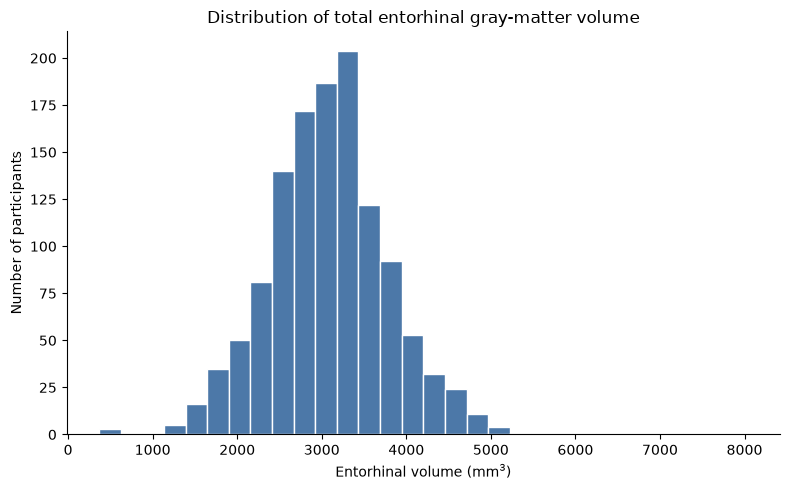

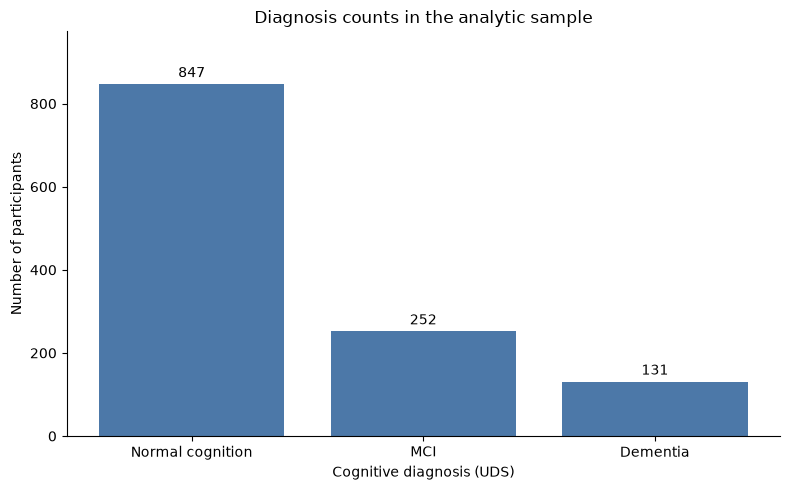

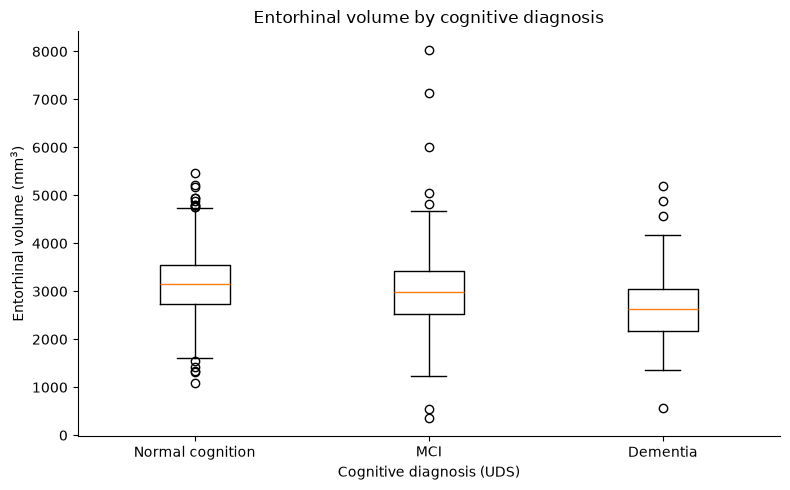

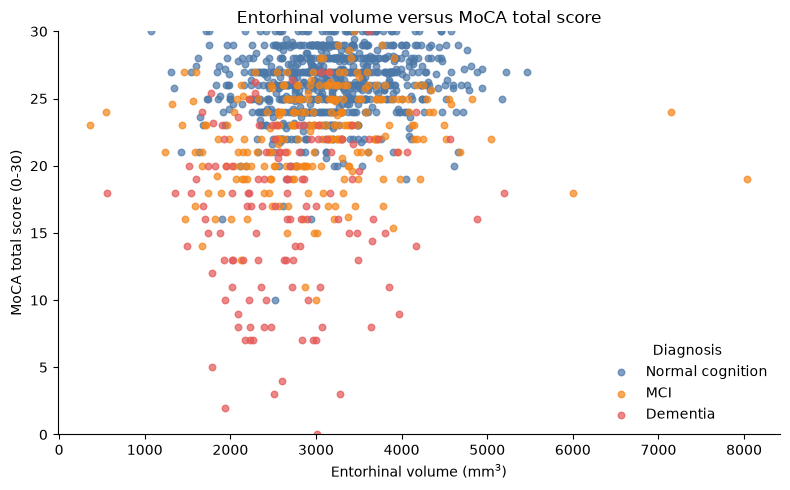

Saved figures to \\wsl.localhost\Ubuntu\home\benyamin\Projects\statistics\reports\phase_1\figures


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

FIG_DIR = Path(".") / "figures"
FIG_DIR.mkdir(exist_ok=True)

plot_df = uds_q.merge(
    mri_q[["NACCID", "ENTORHINAL_GVOL_TOTAL"]],
    on="NACCID",
    how="inner",
)
diag_order = ["Normal cognition", "MCI", "Dementia"]
diag_map = {
    1: "Normal cognition",
    3: "MCI",
    4: "Dementia",
}
plot_df["diagnosis_label"] = plot_df["NACCUDSD"].map(diag_map)
plot_main = plot_df[plot_df["diagnosis_label"].isin(diag_order)].copy()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    plot_df["ENTORHINAL_GVOL_TOTAL"].dropna(),
    bins=30,
    color="#4C78A8",
    edgecolor="white",
)
ax.set_title("Distribution of total entorhinal gray-matter volume")
ax.set_xlabel("Entorhinal volume (mm$^3$)")
ax.set_ylabel("Number of participants")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_entorhinal_hist.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
counts = plot_main["diagnosis_label"].value_counts().reindex(diag_order)
ax.bar(counts.index, counts.values, color="#4C78A8")
ax.set_title("Diagnosis counts in the analytic sample")
ax.set_xlabel("Cognitive diagnosis (UDS)")
ax.set_ylabel("Number of participants")
ax.set_ylim(0, max(counts.values) * 1.15)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for i, v in enumerate(counts.values):
    ax.text(i, v + max(counts.values) * 0.02, str(int(v)), ha="center")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_diagnosis_counts.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
data_box = [
    plot_main.loc[plot_main["diagnosis_label"] == g, "ENTORHINAL_GVOL_TOTAL"].dropna().values
    for g in diag_order
]
ax.boxplot(data_box, showfliers=True)
ax.set_xticks(range(1, len(diag_order) + 1))
ax.set_xticklabels(diag_order)
ax.set_title("Entorhinal volume by cognitive diagnosis")
ax.set_xlabel("Cognitive diagnosis (UDS)")
ax.set_ylabel("Entorhinal volume (mm$^3$)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_entorhinal_by_diagnosis.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sc = plot_main.dropna(subset=["ENTORHINAL_GVOL_TOTAL", "MOCATOTS_clean"])
colors = {
    "Normal cognition": "#4C78A8",
    "MCI": "#F58518",
    "Dementia": "#E45756",
}
for g in diag_order:
    part = sc[sc["diagnosis_label"] == g]
    ax.scatter(
        part["ENTORHINAL_GVOL_TOTAL"],
        part["MOCATOTS_clean"],
        s=22,
        alpha=0.7,
        label=g,
        color=colors[g],
    )
ax.set_title("Entorhinal volume versus MoCA total score")
ax.set_xlabel("Entorhinal volume (mm$^3$)")
ax.set_ylabel("MoCA total score (0-30)")
ax.set_ylim(0, 30)
ax.legend(title="Diagnosis", frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_entorhinal_vs_moca.png", dpi=200)
plt.show()

print("Saved figures to", FIG_DIR.resolve())

<div dir="rtl" lang="fa">

#### نکته‌های مصورسازی

- محور عمودی نمودار میله‌ای از صفر شروع شده تا تفاوت فراوانی‌ها اغراق نشود.
- در پراکنش، محور MoCA در بازه ۰ تا ۳۰ مانده چون بازه معتبر آزمون همین است.
- گروه Impaired-not-MCI به‌خاطر تعداد خیلی کم در نمودارهای گروهی اصلی نیامده تا نمودار گمراه‌کننده نشود؛ تعدادش جدا در جدول‌ها گزارش شده است.
- هیچ نمودار سه‌بعدی استفاده نشده است.

</div>

<div dir="rtl" lang="fa">

### تسک ۹ — مقایسه توصیفی اولیه

حداقل یک مقایسه توصیفی بین گروه‌ها انجام می‌دهیم: حجم کل انتورینال بین شناخت طبیعی، MCI و دمانس.

در این فاز فقط توصیف می‌کنیم. آزمون فرض، فاصله اطمینان یا ادعای معناداری آماری نمی‌آید.

</div>

In [14]:
cmp_entorhinal_by_dx = (
    plot_main
    .dropna(subset=["diagnosis_label", "ENTORHINAL_GVOL_TOTAL"])
    .groupby("diagnosis_label", observed=True)["ENTORHINAL_GVOL_TOTAL"]
    .agg(
        n="count",
        mean="mean",
        median="median",
        sd="std",
        q1=lambda s: s.quantile(0.25),
        q3=lambda s: s.quantile(0.75),
    )
    .reindex(diag_order)
    .round(2)
    .reset_index()
)

cmp_moca_by_dx = (
    plot_main
    .dropna(subset=["diagnosis_label", "MOCATOTS_clean"])
    .groupby("diagnosis_label", observed=True)["MOCATOTS_clean"]
    .agg(n="count", mean="mean", median="median", sd="std")
    .reindex(diag_order)
    .round(2)
    .reset_index()
)

print("Entorhinal volume by diagnosis (descriptive only)")
display(cmp_entorhinal_by_dx)
print("MoCA by diagnosis (descriptive only)")
display(cmp_moca_by_dx)

Entorhinal volume by diagnosis (descriptive only)


,diagnosis_label,n,mean,median,sd,q1,q3
0,Normal cognition,846,3164.74,3150.5,642.57,2743.75,3546.0
1,MCI,252,3014.22,2993.5,883.09,2522.50,3428.5
2,Dementia,131,2668.63,2629.0,748.04,2178.50,3054.5


MoCA by diagnosis (descriptive only)


,diagnosis_label,n,mean,median,sd
0,Normal cognition,842,26.17,26.2,2.36
1,MCI,251,22.40,23.0,3.38
2,Dementia,128,16.48,17.0,6.10


<div dir="rtl" lang="fa">

#### تفسیر توصیفی بدون استنباط

جدول بالا و باکس‌پلات تسک ۸ فقط می‌گویند توزیع حجم انتورینال و نمره MoCA بین گروه‌های تشخیصی چگونه به نظر می‌رسد.


اگر میانگین/میانه حجم در دمانس کمتر از شناخت طبیعی دیده شود، این فقط یک الگوی توصیفی اولیه است، نه نتیجه استنباطی.

</div>

<div dir="rtl" lang="fa">

### تسک ۱۰ — نهایی کردن سؤال آماری

با شناختی که تا اینجا از داده به دست آمد، سؤال اصلی این‌طور نهایی می‌شود:

**سؤال نهایی:**  
در شرکت‌کنندگان زیرنمونه NACC که هم UDS و هم MRI دارند، آیا مجموع حجم ماده خاکستری قشر انتورینال با نمره معتبر MoCA ارتباط دارد، و آیا توزیع این حجم بین گروه‌های شناخت طبیعی، MCI و دمانس تفاوت توصیفی دارد؟

#### چرا این سؤال با داده موجود مناسب است؟

1. هر دو وجه لازم موجودند و با `NACCID` دقیقاً روی ۱۲۳۷ نفر مشترک منطبق‌اند.
2. متغیر پاسخ (`MOCATOTS`) بعد از حذف کدهای نامعتبر قابل استفاده است.
3. متغیر MRI اصلی (`ENTORHINAL_GVOL_TOTAL`) در فایل موجود است؛ هرچند هیپوکامپ موجود نبود و همین انتخاب توجیه دارد.
4. متغیر گروه‌بندی (`NACCUDSD`) تشخیص استاندارد UDS را می‌دهد؛ گروه ۲ به‌خاطر حجم خیلی کم از مقایسه اصلی کنار گذاشته می‌شود.
5. واحد مشاهده فرد است و مشکل تکرار مراجعه در این زیرنمونه وجود ندارد.

#### محدودسازی نسبت به نسخه خیلی کلی

سؤال از حالت کلی مثل «بررسی داده سلامت» خارج شده و به این موارد محدود شده است:

- یک شاخص MRI مشخص: حجم انتورینال
- یک نمره شناخت مشخص: MoCA
- سه گروه تشخیصی اصلی: طبیعی، MCI، دمانس

این سؤال برای فازهای بعد هم قابل ادامه‌دادن است: توصیف در فاز ۱، احتمال و توزیع در فاز ۲، برآورد/آزمون در فاز ۳، و رگرسیون در فاز ۴.

</div>

In [ ]:
final_question_note = {
    "response": "MOCATOTS_clean",
    "explanatory": "ENTORHINAL_GVOL_TOTAL",
    "grouping": "NACCUDSD (1,3,4)",
    "unit": "participant (NACCID)",
    "n_multimodal": int(plot_df["NACCID"].nunique()),
    "n_for_association": int(
        plot_df.dropna(subset=["ENTORHINAL_GVOL_TOTAL", "MOCATOTS_clean"]).shape[0]
    ),
    "n_for_group_comparison": int(
        plot_main.dropna(subset=["ENTORHINAL_GVOL_TOTAL", "diagnosis_label"]).shape[0]
    ),
}

final_question_note

<div dir="rtl" lang="fa">

## الزامات ویژه مسیر ج

### ج۱ — نقشه زیرمجموعه UDS و MRI

فایل‌های تحویلی تیم دستیاری:

1. `udslong_imputed.csv` : وجه بالینی UDS
2. `mriscanclean.csv` : وجه تصویربرداری MRI
3. `combined_adjacency_matrix.csv` : ماتریس همسایگی نواحی مغز (داده فردی نیست)

#### دسته‌بندی متغیرهای UDS

در فایل UDS حدود ۱۸۰ ستون وجود دارد. برای نقشه کلی، خانواده‌های اصلی این‌ها هستند:

- **جمعیت‌شناختی:** `NACCID`, `NACCAGE`, `SEX`, `EDUC`, `RACE`, `HISPANIC`
- **پزشکی / سابقه سلامت:** مثلاً فشارخون، دیابت، سکته، مصرف دخانیات و داروهای ثبت‌شده در UDS
- **عملکردی / رفتاری:** مثلاً استقلال، مقیاس‌های عملکردی و آیتم‌های مرتبط با کارکرد روزمره
- **شناختی / تشخیصی:** `MOCATOTS`, `NACCUDSD`, `CDRGLOB`, `CDRSUM` و سایر نمرات عصب‌روان‌شناختی مثل Trail Making

متغیرهای اصلی سؤال پروژه از میان این خانواده‌ها انتخاب شده‌اند؛ لازم نیست همه ۱۸۰ ستون وارد تحلیل شوند.

#### دسته‌بندی متغیرهای MRI

در فایل MRI ستون‌ها عمدتاً دو نوع اندازه‌گیری برای نواحی قشری چپ و راست هستند:

- `_GVOL` : حجم ماده خاکستری ناحیه (mm³)
- `_AVGTH` : ضخامت متوسط قشر ناحیه (mm)

پیشوند:

- `LH_` = نیمکره چپ
- `RH_` = نیمکره راست

برای سؤال پروژه:

- متغیر اصلی: مجموع حجم انتورینال چپ و راست
- پشتیبان: ضخامت انتورینال و حجم/ضخامت پاراهیپوکامپ

ماتریس adjacency نشان می‌دهد کدام نواحی از نظر آناتومی همسایه فرض شده‌اند و برای توصیف ساختار نواحی مفید است، نه به‌عنوان ردیف مشاهده فردی.

</div>

In [ ]:
mri_gvol = [c for c in mri.columns if c.endswith("_GVOL")]
mri_avgth = [c for c in mri.columns if c.endswith("_AVGTH")]

file_map = pd.DataFrame([
    {"file": "udslong_imputed.csv", "role": "UDS clinical", "n_rows": len(uds), "n_cols": uds.shape[1]},
    {"file": "mriscanclean.csv", "role": "MRI quantitative", "n_rows": len(mri), "n_cols": mri.shape[1]},
    {"file": "combined_adjacency_matrix.csv", "role": "region adjacency", "n_rows": adj.shape[0], "n_cols": adj.shape[1]},
])

mri_family = pd.Series({
    "n_GVOL_columns": len(mri_gvol),
    "n_AVGTH_columns": len(mri_avgth),
    "has_NACCID": "NACCID" in mri.columns,
    "has_NACCUDSD": "NACCUDSD" in mri.columns,
    "has_hippocampus": any("HIPPO" in c.upper() for c in mri.columns),
    "has_ICV_or_TIV": any(x in "".join(mri.columns).upper() for x in ["ICV", "TIV", "ETIV"]),
})

display(file_map)
display(mri_family.to_frame("value"))

,file,role,n_rows,n_cols
0,udslong_imputed.csv,UDS clinical,1237,180
1,mriscanclean.csv,MRI quantitative,1237,127
2,combined_adjacency_matrix.csv,region adjacency,62,62


,value
n_GVOL_columns,62
n_AVGTH_columns,62
has_NACCID,True
has_NACCUDSD,True
has_hippocampus,True
has_ICV_or_TIV,False


<div dir="rtl" lang="fa">

### ج۲ — ساختار شرکت‌کننده و مراجعه

در پایگاه کامل NACC ممکن است هر شرکت‌کننده چند مراجعه سالانه داشته باشد. اما در زیرنمونه این درس، فایل‌ها طوری آماده‌سازی شده‌اند که هر `NACCID` فقط یک ردیف دارد.

بنابراین:

- تعداد شرکت‌کنندگان یکتا = تعداد ردیف‌ها
- تعداد مراجعه به ازای هر فرد در این فایل = ۱
- نیازی به انتخاب بین چند مراجعه نیست

#### قاعده انتخاب مشاهده اصلی برای فازهای بعد

چون در این زیرنمونه تکرار مراجعه وجود ندارد، قاعده ساده است:

**هر شرکت‌کننده دقیقاً یک‌بار وارد تحلیل می‌شود؛ کلید یکتایی `NACCID` است.**

اگر بعداً نسخه طولی‌تری داده شود، قاعده جایگزین این خواهد بود: نزدیک‌ترین مراجعه UDS به اسکن MRI، و در صورت تساوی اولین مراجعه مشترک.

</div>

In [ ]:
visit_structure = pd.DataFrame({
    "face": ["UDS", "MRI"],
    "n_rows": [len(uds), len(mri)],
    "n_unique_participants": [uds["NACCID"].nunique(), mri["NACCID"].nunique()],
    "max_rows_per_participant": [
        int(uds.groupby("NACCID").size().max()),
        int(mri.groupby("NACCID").size().max()),
    ],
})

visits_per_person_uds = (
    uds.groupby("NACCID").size().value_counts().sort_index().rename_axis("visits_per_participant").reset_index(name="n_participants")
)

display(visit_structure)
display(visits_per_person_uds)

index_rule = {
    "rule_name": "one_row_per_NACCID",
    "reason": "No repeated NACCID in the TA subset",
    "fallback_if_longitudinal": "nearest UDS visit to MRI scan",
}
index_rule

,face,n_rows,n_unique_participants,max_rows_per_participant
0,UDS,1237,1237,1
1,MRI,1237,1237,1


,visits_per_participant,n_participants
0,1,1237


{'rule_name': 'one_row_per_NACCID',
 'reason': 'No repeated NACCID in the TA subset',
 'fallback_if_longitudinal': 'nearest UDS visit to MRI scan'}

<div dir="rtl" lang="fa">

### ج۳ — اتصال UDS و MRI

کلید اتصال رسمی بین دو وجه، شناسه شرکت‌کننده `NACCID` است.

در بررسی این زیرنمونه:

- همه افراد UDS در MRI هم هستند
- همه افراد MRI در UDS هم هستند
- مورد بدون تطابق دیده نمی‌شود

حجم نمونه نهایی چندوجهی برابر تعداد شرکت‌کنندگان مشترک است.

</div>

In [ ]:
uds_ids = set(uds["NACCID"])
mri_ids = set(mri["NACCID"])
both_ids = uds_ids & mri_ids

merge_flow = pd.DataFrame({
    "stage": [
        "UDS participants",
        "MRI participants",
        "Participants in both faces",
        "UDS only",
        "MRI only",
        "Final multimodal sample",
    ],
    "n": [
        len(uds_ids),
        len(mri_ids),
        len(both_ids),
        len(uds_ids - mri_ids),
        len(mri_ids - uds_ids),
        len(both_ids),
    ],
})

merged = uds_q.merge(
    mri_q[["NACCID", "ENTORHINAL_GVOL_TOTAL", "LH_ENTORHINAL_GVOL_clean", "RH_ENTORHINAL_GVOL_clean"]],
    on="NACCID",
    how="inner",
    validate="one_to_one",
)

display(merge_flow)
print("Merged analytic rows:", len(merged))
print("Unique participants after merge:", merged["NACCID"].nunique())

,stage,n
0,UDS participants,1237
1,MRI participants,1237
2,Participants in both faces,1237
3,UDS only,0
4,MRI only,0
5,Final multimodal sample,1237


Merged analytic rows: 1237
Unique participants after merge: 1237


<div dir="rtl" lang="fa">

### ج۴ — داده‌های گمشده و انتخاب شدن نمونه چندوجهی

دو موضوع جدا باید روشن شود:

1. **گمشدگی متغیرهای اصلی داخل همین زیرنمونه چندوجهی**
2. **آیا کسانی که MRI دارند با کسانی که MRI ندارند فرق دارند؟**

نکته مهم و درست برای این پروژه:

در فایل‌های تحویلی مسیر ج، همه ۱۲۳۷ نفر هم UDS دارند و هم MRI. بنابراین داخل همین زیرنمونه، گروه «بدون MRI» وجود ندارد و مقایسه توصیفی افراد دارای MRI با افراد فاقد MRI **درون این فایل‌ها ممکن نیست**. انتخاب چندوجهی قبل از تحویل داده انجام شده است. این خودش یک محدودیت انتخاب است و باید گزارش شود.

آنچه می‌توانیم بررسی کنیم:

- درصد گمشدگی/نامعتبر بودن متغیرهای اصلی بعد از recode
- توصیف همین نمونه چندوجهی از نظر سن، جنس، تحصیلات و تشخیص

</div>

In [ ]:
missing_main_both = pd.DataFrame({
    "variable": [
        "NACCAGE",
        "SEX",
        "EDUC_clean",
        "NACCUDSD",
        "MOCATOTS_clean",
        "ENTORHINAL_GVOL_TOTAL",
    ],
    "n_missing": [
        int(merged["NACCAGE"].isna().sum()),
        int(merged["SEX"].isna().sum()),
        int(merged["EDUC_clean"].isna().sum()),
        int(merged["NACCUDSD"].isna().sum()),
        int(merged["MOCATOTS_clean"].isna().sum()),
        int(merged["ENTORHINAL_GVOL_TOTAL"].isna().sum()),
    ],
})
missing_main_both["percent_missing"] = (
    missing_main_both["n_missing"] / len(merged) * 100
).round(2)

selection_note = pd.DataFrame({
    "comparison": ["Has MRI vs No MRI within TA subset"],
    "possible": [False],
    "reason": ["All 1237 delivered participants already have both UDS and MRI"],
})

multimodal_profile = pd.DataFrame({
    "n": [len(merged)],
    "mean_age": [merged["NACCAGE"].mean()],
    "pct_female": [(merged["SEX"] == 2).mean() * 100],
    "mean_educ_clean": [merged["EDUC_clean"].mean()],
    "pct_normal": [(merged["NACCUDSD"] == 1).mean() * 100],
    "pct_mci": [(merged["NACCUDSD"] == 3).mean() * 100],
    "pct_dementia": [(merged["NACCUDSD"] == 4).mean() * 100],
}).round(2)

display(missing_main_both)
display(selection_note)
display(multimodal_profile)

,variable,n_missing,percent_missing
0,NACCAGE,0,0.00
1,SEX,0,0.00
2,EDUC_clean,2,0.16
3,NACCUDSD,0,0.00
4,MOCATOTS_clean,9,0.73
5,ENTORHINAL_GVOL_TOTAL,1,0.08


,comparison,possible,reason
0,Has MRI vs No MRI within TA subset,False,All 1237 delivered participants already have b...


,n,mean_age,pct_female,mean_educ_clean,pct_normal,pct_mci,pct_dementia
0,1237,68.19,59.82,16.26,68.47,20.37,10.59


<div dir="rtl" lang="fa">

### ج۵ — خلاصه مشترک شناختی و تصویربرداری

حداقل یک نمره شناختی از UDS و یک متغیر کمی از MRI را با هم توصیف می‌کنیم:

- شناختی: `MOCATOTS_clean`
- تصویربرداری: `ENTORHINAL_GVOL_TOTAL`

برای هر کدام دامنه، مرکز، پراکندگی و اشاره به نقاط غیرعادی گزارش می‌شود. نمودارهای مرتبط قبلاً در تسک ۸ ساخته شده‌اند؛ اینجا خلاصه عددی مشترک را متمرکز می‌کنیم.

</div>

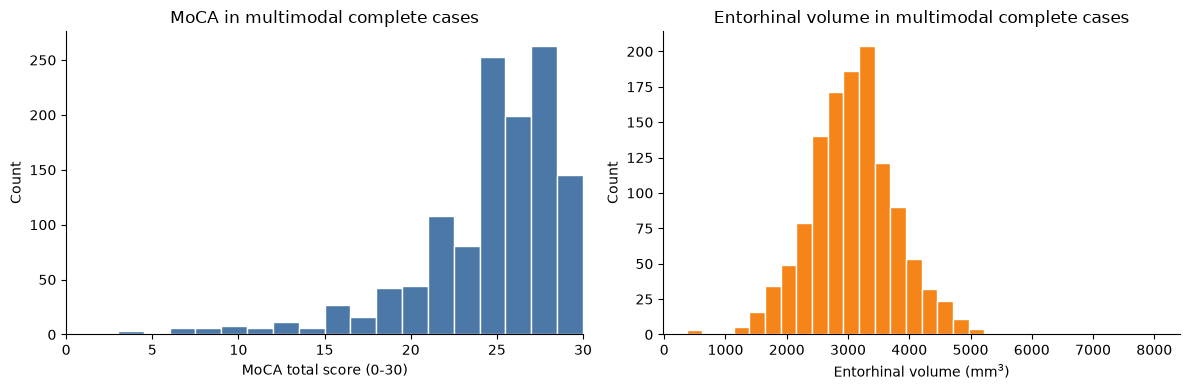

,variable,n,min,max,mean,median,sd,q1,q3,iqr,n_tukey_outliers
0,MOCATOTS_clean,1227,0.0,30.0,24.39,25.4,4.43,23.0,27.0,4.0,76
1,ENTORHINAL_GVOL_TOTAL,1227,366.0,8036.0,3083.88,3075.0,723.96,2630.0,3492.0,862.0,22


Complete cases used for joint summary: 1227


In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

joint = merged.dropna(subset=["MOCATOTS_clean", "ENTORHINAL_GVOL_TOTAL"]).copy()

def summarize_one(s, name):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < lower) | (s > upper)).sum())
    return {
        "variable": name,
        "n": int(s.count()),
        "min": s.min(),
        "max": s.max(),
        "mean": s.mean(),
        "median": s.median(),
        "sd": s.std(ddof=1),
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "n_tukey_outliers": n_out,
    }

joint_summary_table = pd.DataFrame([
    summarize_one(joint["MOCATOTS_clean"], "MOCATOTS_clean"),
    summarize_one(joint["ENTORHINAL_GVOL_TOTAL"], "ENTORHINAL_GVOL_TOTAL"),
]).round(2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(joint["MOCATOTS_clean"], bins=20, color="#4C78A8", edgecolor="white")
axes[0].set_title("MoCA in multimodal complete cases")
axes[0].set_xlabel("MoCA total score (0-30)")
axes[0].set_ylabel("Count")
axes[0].set_xlim(0, 30)

axes[1].hist(joint["ENTORHINAL_GVOL_TOTAL"], bins=30, color="#F58518", edgecolor="white")
axes[1].set_title("Entorhinal volume in multimodal complete cases")
axes[1].set_xlabel("Entorhinal volume (mm$^3$)")
axes[1].set_ylabel("Count")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(Path("figures") / "fig5_joint_moca_entorhinal.png", dpi=200)
plt.show()

display(joint_summary_table)
print("Complete cases used for joint summary:", len(joint))

<div dir="rtl" lang="fa">

#### جمع‌بندی الزامات مسیر ج

- ج۱: فایل‌ها معرفی و متغیرها دسته‌بندی شدند.
- ج۲: واحد مشاهده فرد است؛ در این زیرنمونه هر نفر یک ردیف دارد.
- ج۳: اتصال با `NACCID` کامل است و نمونه نهایی چندوجهی ۱۲۳۷ نفر است.
- ج۴: گمشدگی متغیرهای اصلی بعد از recode کم است؛ مقایسه MRIدار در برابر بدون MRI داخل این فایل‌ها ممکن نیست چون همه MRI دارند.
- ج۵: MoCA و حجم انتورینال به‌صورت مشترک با جدول و نمودار توصیف شدند.

</div>